In [254]:
import os

import numpy as np

import torch
from torch.utils.data import Dataset, DataLoader, random_split
import torch.nn as nn
import torch.optim as optim

from music21 import converter, note
from scipy.signal import butter, filtfilt

import matplotlib.pyplot as plt

In [255]:

seed = 123
np.random.seed(seed)
_ = torch.manual_seed(seed)
_ = torch.cuda.manual_seed(seed)

In [256]:

# Work on GPU if it is available in the machine, otherwise run on CPU
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

In [257]:

# Definition of hyper-parameters
hparams = {
    'seq_len_dataset': 48,
    'batch_size':8,
    'channels':64,
    'latent_dim':85,
    'frp_len': 512,
    'vocab_size': 130,
    'n_layers_encoder': 7,
    'embedding_dim': 128,
    'n_layers_gru': 2,
    'hidden_dim_gru': 2048,
    'seq_len': 24,
    'vocab_size_Trp': 7,
    
    'num_epochs':10,
    'lambda_trp': 1.0,
    'lambda_tmidi': 1.0,
    'learning_rate':1e-4,
}

Definition of the Pytorch Dataset and DataLoader

In [258]:

# Extract the pitches from 1 bar
def extract_pitches_1bar(notes):
    seq_len = hparams['seq_len_dataset']
    measeure_length = 4 # time signature is 4/4, so 4 beats per measure

    pitch_vector = np.zeros(seq_len, dtype=np.float32)

    onsets = []
    pitches = []

    for n in notes:
        if isinstance(n, note.Note):
            onsets.append(n.offset)
            pitches.append(n.pitch.midi)

    # Convert note onset (offset in beats) to a grid position [0..47]
    norm_onsets = np.mod(onsets, measeure_length) / measeure_length
    quant_onsets = np.round(norm_onsets * (seq_len - 1)).astype(int)

    # Fill the pitch_vector
    # Sustain each note until the next onset
    for i, onset in enumerate(quant_onsets):
        if i + 1 < len(quant_onsets):
            end = quant_onsets[i + 1]
        else:
            end = seq_len
        pitch_vector[onset:end] = pitches[i]
    
    return pitch_vector, quant_onsets, pitches

In [259]:

# Compute the relative pitch function for 2nd bar
def compute_frp(onsets, pitches):
    # Definition of the constant variables
    frp_len = hparams['frp_len']
    filter_cutoff = 1/50
    filter_order = 5

    # Piecewise-linear interpolation
    x = np.linspace(onsets.min(), onsets.max(), frp_len)
    y = np.interp(x, onsets, pitches)

    # Low-pass Butterworth filtering
    # to smooth the linear interpolation
    b, a = butter(filter_order, filter_cutoff, btype='low')
    y_smooth = filtfilt(b, a, y)

    # Normalization
    # Find midpoint in the curve range
    pitch_range = y_smooth.max() - y_smooth.min()
    middle_val = y_smooth.min() + pitch_range/2

    # Substract midpoint and divide by 12
    # 12 because 12 semitones = 1 octave
    frp = (y_smooth - middle_val) / 12.0

    # Return the function
    return frp.astype(np.float32)

In [260]:
# Process the 2 bars
def process_bars(midi_path):
    score = converter.parse(midi_path)

    # Extract 1st and 2nd bar from score
    bar1 = score.measure(1).flatten().notes
    bar2 = score.measure(2).flatten().notes

    # Convert bars into 48-step pitch vectors
    bar1_pitch_vector, _, _ = extract_pitches_1bar(bar1)
    bar2_pitch_vector, bar2_onsets, bar2_pitches = extract_pitches_1bar(bar2)

    # Compute the FRP for 2nd bar
    frp = compute_frp(bar2_onsets, bar2_pitches)

    # Return pitch vectors as numpy arrays
    return np.array(bar1_pitch_vector), np.array(bar2_pitch_vector), np.array(frp)

In [261]:

# Definition the Pytorch Dataset
class CombinedDataset(Dataset):
    """
    This dataset combines samples from Irish Folk Music Dataset and the synthetic dataset.

    Returns for each sample:
    - past_pitches (from 1st bar, encoder input, len 48)
    - curr_pitches (from 2nd bar, decoder target, len 48)
    - frp (from 2nd bar, pitch curve, len 512)
    - midi_path
    """
    def __init__(self, irish_root, synthetic_root, seq_len=hparams['seq_len_dataset'], frp_len=hparams['frp_len']):
        self.seq_len = seq_len
        self.frp_len = frp_len

        # Collect all MIDI files from both datasets
        self.files = []
        for root in [irish_root, synthetic_root]:
            for f in os.listdir(root):
                if f.endswith(".mid") or f.endswith(".midi"):
                    self.files.append(os.path.join(root, f))

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        midi_path = self.files[idx]

        # Extract pitches from both bars and frp from 2nd bar
        past_pitches, curr_pitches, frp = process_bars(midi_path)

        return past_pitches, curr_pitches, frp, midi_path

In [262]:

# Definition of the dataset folders
irish_root = 'C:/Users/cristinj/OneDrive - Universitetet i Oslo/Documents/Project1/melodic-contour-generation-based-on-sketches/irishtunes_dataset'
synthetic_root = 'C:/Users/cristinj/OneDrive - Universitetet i Oslo/Documents/Project1/melodic-contour-generation-based-on-sketches/synthetics_dataset'

# Create one dataset for all data
combined_dataset = CombinedDataset(irish_root, synthetic_root)

# Determine split sizes
total_size = len(combined_dataset)
train_size = int(0.7 * total_size)
val_size = int(0.2 * total_size)
test_size = total_size - train_size - val_size

# Split the dataset
train_dataset, val_dataset, test_dataset = random_split(
    combined_dataset, [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

# Dataloaders initialization
train_dataloader = torch.utils.data.DataLoader(
    dataset=train_dataset,
    batch_size=hparams['batch_size'],
    shuffle=True,
    drop_last=False,
)

val_dataloader = torch.utils.data.DataLoader(
    dataset=val_dataset,
    batch_size=hparams['batch_size'],
    shuffle=False,
    drop_last=True,
)

test_dataloader = torch.utils.data.DataLoader(
    dataset=test_dataset,
    batch_size=hparams['batch_size'],
    shuffle=False,
    drop_last=True,
)

In [263]:
print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))


Train samples: 10
Validation samples: 3
Test samples: 2


In [264]:
# Show one training sample
past_pitches, curr_pitches, frp, midi_path = train_dataset[2]

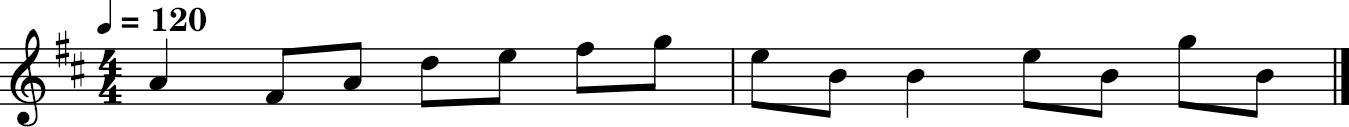

C:/Users/cristinj/OneDrive - Universitetet i Oslo/Documents/Project1/melodic-contour-generation-based-on-sketches/irishtunes_dataset\Cooley's_0_2bars_25.midi
[69. 69. 69. 69. 69. 69. 69. 69. 69. 69. 69. 69. 66. 66. 66. 66. 66. 66.
 69. 69. 69. 69. 69. 69. 74. 74. 74. 74. 74. 76. 76. 76. 76. 76. 76. 78.
 78. 78. 78. 78. 78. 79. 79. 79. 79. 79. 79. 79.]
[76. 76. 76. 76. 76. 76. 71. 71. 71. 71. 71. 71. 71. 71. 71. 71. 71. 71.
 71. 71. 71. 71. 71. 71. 76. 76. 76. 76. 76. 71. 71. 71. 71. 71. 71. 79.
 79. 79. 79. 79. 79. 71. 71. 71. 71. 71. 71. 71.]
(512,)


In [265]:
score = converter.parse(str(midi_path))
score.show()

print(midi_path)

print(past_pitches)
print(curr_pitches)
print(frp.shape)

#plt.figure(figsize=(8, 3))
#plt.plot(frp[0])
#plt.title("Relative Pitch Function (Frp)")
#plt.xlabel("512 samples across 1st measure")
#plt.ylabel("Relative pitch (octaves)")
#plt.grid(True)
#plt.show()

C:/Users/cristinj/OneDrive - Universitetet i Oslo/Documents/Project1/melodic-contour-generation-based-on-sketches/irishtunes_dataset\Cooley's_0_2bars_13.midi


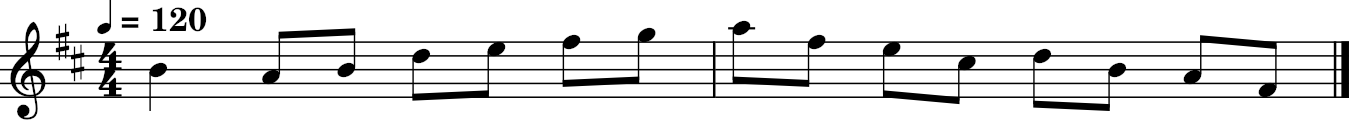

torch.Size([48])
torch.Size([48])
torch.Size([512])


In [266]:
past_pitches, curr_pitches, frp, midi_path = next(iter(train_dataloader))

print(midi_path[0])
score = converter.parse(str(midi_path[0]))
score.show()

print(past_pitches[0].shape)
print(curr_pitches[0].shape)
print(frp[0].shape)

Definition of the architecture

In [267]:
# Encoder
# Residual block for Qcurve
class QResBlock(nn.Module):
    """
    Residual block with 3 conv layers:
    input
    -> Conv1d(kernel = 3) -> LeakyReLU
    -> Conv1d(kernel = 3) -> LeakyReLU
    -> Conv1d(kernel = 3) -> LeakyReLU
    -> skip connection -> LeakyReLU
    -> output
    """
    def __init__(
            self,
            in_channels: int,
            out_channels: int,
            ) -> None:
        
        super(QResBlock, self).__init__()

        self.in_channels = in_channels
        self.out_channels = out_channels
        self.middle_channels = self.out_channels//2
    
        self.conv1 = nn.Conv1d(in_channels=self.in_channels, out_channels=self.middle_channels, kernel_size=1, stride=1, dilation=1, padding=0, bias=True)
        self.batchNorm1 = nn.BatchNorm1d(num_features=self.middle_channels)
        self.act1 = nn.LeakyReLU(inplace=True)
        
        self.conv2 = nn.Conv1d(in_channels=self.middle_channels, out_channels=self.middle_channels, kernel_size=3, stride=1, dilation=1, padding=1, bias=True)
        self.batchNorm2 = nn.BatchNorm1d(num_features=self.middle_channels)
        self.act2 = nn.LeakyReLU(inplace=True)
        
        self.conv3 = nn.Conv1d(in_channels=self.middle_channels, out_channels=self.out_channels, kernel_size=1, stride=1, dilation=1, padding=0, bias=True)
        self.batchNorm3 = nn.BatchNorm1d(num_features=self.out_channels)
        self.act3 = nn.LeakyReLU(inplace=True)
        
        self.act4 = nn.LeakyReLU(inplace=True)

        self.skip_conv = nn.Conv1d(in_channels=self.in_channels, out_channels=self.out_channels, kernel_size=1, stride=1, dilation=1, padding=0, bias=True)


    def forward(self, x):
        #print(x.shape) # [5, 1, 512]

        skip = self.skip_conv(x)

        out = self.conv1(x)
        out = self.act1(out)
        
        #print(out.shape) # [5, 32, 512]
        out = self.conv2(out)
        out = self.act2(out)

        #print(out.shape) # [5, 32, 512]
        out = self.conv3(out)
        out = self.act3(out)

        #print(out.shape) # [5, 64, 512]
        out = out + skip  # residual connection
        out = self.act4(out)
        return out
    

In [268]:
# Encoder
# Pitch curve encoder
class Qcurve(nn.Module):
    """
    Qcurve encodes the Frp from input curve into latent pitch vector Zrp
    CNN composed by 7 residual blocks (QResBlock)
    """
    def __init__(
            self,
            channels: int,
            latent_dim: int,
            frp_len: int,
            n_layers: int,
            ) -> None:

        super(Qcurve, self).__init__()

        self.base_channels = channels
        self.latent_dim = latent_dim
        self.frp_len = frp_len
        self.n_layers = n_layers

        self.curve_encoder = nn.Sequential()
        
        current_channels = 1

        for i in range(self.n_layers):
            # Add 7 layers of residual blocks to the curve_encoder
            out_channels = self.base_channels * 2**i # out_channels gets bigger with each layer
            resBlock = QResBlock(in_channels=current_channels, out_channels=out_channels)
            self.curve_encoder.add_module(f'layer{i}', resBlock)
            current_channels = out_channels
        
        self.mu = nn.Conv1d(in_channels=current_channels, out_channels=self.latent_dim, kernel_size=self.frp_len)
        self.logvar = nn.Conv1d(in_channels=current_channels, out_channels=self.latent_dim, kernel_size=self.frp_len)
    
    def reparametrize(
            self,
            mu:torch.Tensor,
            logvar:torch.Tensor,
            ) -> torch.Tensor:
        # Given mean and logvar returns z
        # reparameterization trick: instead of sampling from Q(z|X), sample epsilon = N(0,I)
        # mu, logvar: mean and log of variance of Q(z|X)

        # The factor 1/2 in the exponent ensures that the distribution has unit variance
        std = torch.exp(0.5 * logvar)
        # Random sample
        eps = torch.randn_like(std)
        return mu + std * eps

    def forward(self, x: torch.Tensor):
        #print(x.shape) # [5, 1, 512]
        out = self.curve_encoder(x)
        #print(out.shape) # [5, 4096, 512]

        x_mu = self.mu(out).squeeze(-1)
        #print(x_mu.shape) # [5, 85]
        x_logvar = self.logvar(out).squeeze(-1)
        #print(x_logvar.shape) # [5, 85]
        z = self.reparametrize(x_mu, x_logvar)
        #print(z.shape) # [5, 85]

        return z

In [269]:
# Encoder
# Context encoder
class Qcontext(nn.Module):
    """
    Qcontext encodes the past context bar Mprev into the latent context vector Zc
    Pipeline:
    - 1 embedding layer of size 128
    - 2 layers of bidirectional GRUs (2048 units each)
    - 1 dense layer
    """

    def __init__(self,
                 vocab_size: int,
                 embedding_dim: int,
                 hidden_dim_gru: int,
                 n_layers_gru: int,
                 latent_dim: int,
                 ) -> None:
        
        super(Qcontext, self).__init__()

        self.vocab_size = vocab_size
        self.embedding_dim = embedding_dim
        self.hidden_dim_gru = hidden_dim_gru
        self.n_layers_gru = n_layers_gru
        self.latent_dim = latent_dim

        self.embedding = nn.Embedding(num_embeddings=self.vocab_size, embedding_dim=self.embedding_dim)
        self.gru = nn.GRU(input_size=self.embedding_dim, hidden_size=self.hidden_dim_gru, num_layers=self.n_layers_gru, batch_first=True, bidirectional=True)

        self.mu = nn.Linear(in_features=self.hidden_dim_gru*2, out_features=self.latent_dim)
        self.logvar = nn.Linear(in_features=self.hidden_dim_gru*2, out_features=self.latent_dim)

    def reparametrize(
            self,
            mu:torch.Tensor,
            logvar:torch.Tensor,
            ) -> torch.Tensor:
        # Given mean and logvar returns z
        # reparameterization trick: instead of sampling from Q(z|X), sample epsilon = N(0,I)
        # mu, logvar: mean and log of variance of Q(z|X)

        # The factor 1/2 in the exponent ensures that the distribution has unit variance
        std = torch.exp(0.5 * logvar)
        # Random sample
        eps = torch.randn_like(std)
        return mu + std * eps

    def forward(self, x: torch.Tensor):
        #print(x.shape) # [8, 1, 48]
        embed = self.embedding(x).squeeze(1)
        #print(embed.shape) # [8, 48, 128]

        out, _ = self.gru(embed)
        #print(out.shape) # [8, 48, 4096]

        h = out[:, -1, :] # take last timestep as context summary
        #print(h.shape) # [8, 4096]

        h_mu = self.mu(h)
        #print(h_mu.shape) # [8, 85]
        h_logvar = self.logvar(h)
        #print(h_logvar.shape) # [8, 85]
        z = self.reparametrize(h_mu, h_logvar)
        #print(z.shape) # [8, 85]
    
        return z

In [270]:
# Decoder
# Pitch decoder
class Prp(nn.Module):
    """
    Prp decodes the Zrp vector into the relative pitch tokens Trp
    Has 2 layers of unidirectional GRUs (2048 units each)
    Uses cross-entropy losses during training
    """

    def __init__(self,
                 latent_dim: int,
                 vocab_size_Trp: int,
                 seq_len: int,
                 hidden_dim_decoder: int,
                 n_layers: int,
                 ) -> None:
        
        super(Prp, self).__init__()

        self.latent_dim = latent_dim
        self.vocab_size_Trp = vocab_size_Trp
        self.seq_len = seq_len
        self.hidden_dim_decoder = hidden_dim_decoder
        self.n_layers = n_layers

        self.gru = nn.GRU(input_size=self.latent_dim, hidden_size=self.hidden_dim_decoder, num_layers=self.n_layers, batch_first=True, bidirectional=False)
        self.fc = nn.Linear(in_features=self.hidden_dim_decoder, out_features=self.vocab_size_Trp)

    def forward(self, z: torch.Tensor):
        #print(z.shape) # [8, 85]

        B = z.size(0)

        # Reshape z so its (B, seq_len, input_size)
        z = z.unsqueeze(1).repeat(1, self.seq_len, 1)
        #print(z.shape) # [8, 24, 85]

        # Initialize hidden state -> input for gru
        h0 = torch.zeros(self.n_layers, B, self.hidden_dim_decoder, device=z.device)

        out, _ = self.gru(z, h0) # output: output tensor, final hidden state tensor
        #print(out.shape) # [8, 24, 2048]
        tokens = self.fc(out)
        #print(tokens.shape) # [8, 24, 7]

        return tokens

In [271]:
# Decoder
# MIDI decoder
class Pmidi(nn.Module):
    """
    Pmidi decodes Trp + Zc into Tmidi
    Has 2 layers of unidirectional GRUs (2048 units each)
    Uses cross-entropy losses during training
    """

    def __init__(self,
                 latent_dim: int,
                 vocab_size_Trp: int,
                 seq_len: int,
                 hidden_dim_decoder: int,
                 n_layers: int,
                 vocab_size: int,
                 ) -> None:
        
        super(Pmidi, self).__init__()

        self.latent_dim = latent_dim
        self.vocab_size_Trp = vocab_size_Trp
        self.seq_len = seq_len
        self.hidden_dim_decoder = hidden_dim_decoder
        self.n_layers = n_layers
        self.vocab_size = vocab_size

        self.gru = nn.GRU(input_size=self.latent_dim + self.vocab_size_Trp, hidden_size=self.hidden_dim_decoder, num_layers=self.n_layers, batch_first=True, bidirectional=False)
        self.fc = nn.Linear(in_features=self.hidden_dim_decoder, out_features=self.vocab_size)
    
    def forward(self, trp, zc: torch.Tensor):
        #print(trp.shape) # [8, 24, 7]
        # trp: [B, seq_len, vocab_size_trp]

        #print(zc.shape) # [8, 85]
        B = zc.size(0)
        # zc: [B, latent_dim] -> expand to seq_len
        zc = zc.unsqueeze(1).repeat(1, self.seq_len, 1)
        #print(zc.shape) # [8, 24, 85]

        # concat trp+zc : [B, seq_len, vocab_size_trp+latent_dim]
        xmidi = torch.cat([zc, trp], dim=-1)
        #print(xmidi.shape) # [8, 24, 92]

        # Initialize hidden state -> input for gru
        h0 = torch.zeros(self.n_layers, B, self.hidden_dim_decoder, device=xmidi.device)

        out, _ = self.gru(xmidi, h0) # output: output tensor, final hidden state tensor
        #print(out.shape) # [8, 24, 2048]
        tokens = self.fc(out)
        #print(tokens.shape) # [8, 24, 130]
        
        return tokens

In [272]:
# Model
class VariationalAutoencoder(nn.Module):
    """
    Model composed by:
    - Encoders: Qcurve, Qcontext
    - Decoders: Prp, Pmidi
    """
    def __init__(self,
                 channels: int,
                 latent_dim: int,
                 vocab_size: int,
                 seq_len: int,
                 frp_len: int,
                 n_layers_encoder: int,
                 embedding_dim: int,
                 n_layers_gru: int,
                 hidden_dim_gru: int,
                 vocab_size_Trp: int,
                 ) -> None:
        
        super(VariationalAutoencoder, self).__init__()

        self.channels = channels
        self.latent_dim = latent_dim
        self.vocab_size = vocab_size
        self.seq_len = seq_len
        self.frp_len = frp_len
        self.n_layers_encoder = n_layers_encoder
        self.embedding_dim = embedding_dim
        self.n_layer_gru = n_layers_gru
        self.hidden_dim_gru = hidden_dim_gru
        self.vocab_size_Trp = vocab_size_Trp

        self.encoder_curve = Qcurve(channels=self.channels, latent_dim=self.latent_dim, frp_len=self.frp_len, n_layers=self.n_layers_encoder)
        self.encoder_context = Qcontext(vocab_size=self.vocab_size, embedding_dim=self.embedding_dim, hidden_dim_gru=self.hidden_dim_gru, n_layers_gru=self.n_layer_gru, latent_dim=self.latent_dim)
        self.decoder_pitch = Prp(latent_dim=self.latent_dim, vocab_size_Trp=self.vocab_size_Trp, seq_len=self.seq_len, hidden_dim_decoder=self.hidden_dim_gru, n_layers=self.n_layer_gru)
        self.decoder_midi = Pmidi(latent_dim=self.latent_dim, vocab_size_Trp= self.vocab_size_Trp, seq_len=self.seq_len, hidden_dim_decoder=self.hidden_dim_gru, n_layers=self.n_layer_gru, vocab_size=self.vocab_size)

    def forward(self, x_curve, x_context: torch.Tensor):
        #print(x_curve.shape) # [8, 1, 512]
        #print(x_context.shape) # [8, 1, 48]

        # Go through encoders
        zrp = self.encoder_curve(x_curve)
        #print(zrp.shape) # [8, 85]
        zc = self.encoder_context(x_context)
        #print(zc.shape) # [8, 85]

        # Go trhough decoders
        trp = self.decoder_pitch(zrp)
        #print(trp.shape) # [8, 24, 7]

        tmidi = self.decoder_midi(trp, zc)

        return trp, tmidi

Training

In [273]:
# Function for extracting ground truth vectors
def compute_true_vectors(bar2_pitches):
    """
    Obtain Tmidi true and Trp true from the ground truth pitch vector of the 2nd bar

    Args:
        bar2_pitches: [B, 48] of MIDI pitches (0 means rest)

    Returns:
        tmidi_true: [B, 24] tokens (0-127 = notes, 128 = hold, 129 = rest)
        trp_true: [B, 24] quantized relative pitch curve'
    """

    # Define constants from hparams
    batch = bar2_pitches.size(0)
    seq_len_dataset = hparams['seq_len_dataset']
    seq_len = hparams['seq_len']

    # Define grid beat ticks
    beat_ticks = [0, 1/4, 1/3, 1/2, 2/3, 3/4] # 6 uneven ticks per beat -> 24 ticks per measure

    # Define quantization bins
    bins = np.array([-9, -5, -1, 0, 1, 5, 9], dtype=np.float32)

    # Define empty vectors
    tmidi_true = torch.zeros(batch, seq_len, dtype=torch.float32)
    trp_true = torch.zeros(batch, seq_len, dtype=torch.float32)

    # Create new grid
    # - In seq_len_dataset = 48, the grid is even, so 12 steps per beat (48/4)
    # - Map the 6 uneven ticks into 12 uniform steps
    tick_indices = np.zeros_like(beat_ticks) # = [0, 3, 4, 6, 8, 9]
    for t in range(len(beat_ticks)):
        tick_indices[t] = round(beat_ticks[t]*12)

    # - Create grid
    grid = [] # = [0, 3, 4, 6, 8, 9, 12, 15, 16, 18, 20, 21, 24, 27, 28, 30, 32, 33, 36, 39, 40, 42, 44, 45]
    for beat in range(4):
        base = beat * 12
        for tick in tick_indices:
            grid += [int(base + tick)]

    for b in range(batch):
        pitches = bar2_pitches[b] # has seq_len_dataset

        # Map bar2_pitches to uneven 24-positions grid
        pitches = pitches[grid] # has seq_len

        # Compute Tmidi_true
        # Go through the pitch vector of each batch
        for t in range(seq_len):
            if pitches[t] == 0:
                tmidi_true[b,t] = 129 # rest condition
            elif t>0 and pitches[t] == pitches[t-1] and pitches[t] != 0:
                tmidi_true[b,t] = 128 # hold condition
            else:
                tmidi_true[b,t] = pitches[t] # MIDI pitch number for onset position
        
        # Compute Trp_true
        # Get the onsets vector
        onsets = np.where((tmidi_true[b] >= 0) & (tmidi_true[b] <= 127))[0]

        if len(onsets) >= 2:
            for pos in range(len(onsets) - 1):
                # For every pair of consecutive onsets in positions i and j = i + n where n > 0, 
                # Calculate the MIDI interval Δ = Tmidi[j] - Tmidi[i]
                i = onsets[pos].item()
                j = onsets[pos + 1].item()
                delta = tmidi_true[b, j] - tmidi_true[b, i]
                n = j - i

                # Then perform a linear interpolation between i + 1 and j (k points), resulting in Trp[k]
                for k in range(i+1, j+1):
                    trp_true[b, k] = delta * ((k-i)/n)
        
        # Quantize Trp_true
        trp_quantizated = torch.zeros(batch, seq_len, dtype=torch.float32)
        bins_tensor = torch.tensor(bins) # convert to tensor so it can be comptatible with trp_true
        for k in range(seq_len):
            diff = np.abs(bins_tensor - trp_true[b, k])
            nearest_bin_idx = np.argmin(diff)
            trp_quantizated[b, k] = nearest_bin_idx
    
    return tmidi_true, trp_quantizated

In [274]:
# Define loss function
def loss_function(trp_pred, trp_true, tmidi_pred, tmidi_true,
                  lambda_trp, lambda_tmidi):
    
    # Flatten batch + time before computing cross-entropies
    B, T, Vtrp  = trp_pred.shape
    _, _, Vmidi = tmidi_pred.shape

    trp_pred_flat   = trp_pred.reshape(B*T, Vtrp)
    trp_true_flat   = trp_true.reshape(B*T)
    tmidi_pred_flat = tmidi_pred.reshape(B*T, Vmidi)
    tmidi_true_flat = tmidi_true.reshape(B*T)

    criterion = nn.CrossEntropyLoss()

    # Compute cross-entropy losses
    loss_trp   = criterion(trp_pred_flat, trp_true_flat)
    loss_tmidi = criterion(tmidi_pred_flat, tmidi_true_flat)

    # Weighted sum
    total_loss = lambda_trp * loss_trp + lambda_tmidi * loss_tmidi

    return total_loss, loss_trp, loss_tmidi

In [275]:
model = VariationalAutoencoder(hparams['channels'], hparams['latent_dim'], hparams['vocab_size'], hparams['seq_len'], hparams['frp_len'], hparams['n_layers_encoder'], hparams['embedding_dim'], hparams['n_layers_gru'], hparams['hidden_dim_gru'], hparams['vocab_size_Trp'])
model = model.to(device)
optimizer = optim.Adam(params=model.parameters(), lr=hparams['learning_rate'])

In [ ]:
# Training loop

# Set to training mode
model.train()

# Create empty loss dictionary
train_loss_avg = {"loss_total": [], "loss_rp": [], "loss_midi": []}
val_loss_avg = {"loss_total": [], "loss_rp": [], "loss_midi": []}

print('Training ...')
for epoch in range(hparams['num_epochs']):
    train_loss_avg["loss_total"].append(0)
    train_loss_avg["loss_rp"].append(0)
    train_loss_avg["loss_midi"].append(0)

    num_batches = len(train_dataloader)

    for batch in train_dataloader:
        # Unpack dataset output
        bar1_pitches, bar2_pitches, frp, midi_path = batch
        
        # Use FRP (pitch curve) and bar1_pitch (context) as inputs
        x_curve = frp.float().unsqueeze(1).to(device)
        x_context = bar1_pitches.int().unsqueeze(1).to(device)

        # Use bar2_pitches to get ground truth vectors
        tmidi_true, trp_true = compute_true_vectors(bar2_pitches)
        trp_true = trp_true.long().to(device)
        tmidi_true = tmidi_true.long().to(device)

        # Forward pass
        trp_pred, tmidi_pred = model(x_curve, x_context)  # [B, seq_len, vocab_size]
        loss_total, loss_rp, loss_midi = loss_function(trp_pred, trp_true, tmidi_pred, tmidi_true, hparams['lambda_trp'], hparams['lambda_tmidi'])

        # Backward pass
        optimizer.zero_grad()
        loss_total.backward()

        optimizer.step()

        train_loss_avg["loss_total"][-1] += loss_total.item()
        train_loss_avg["loss_rp"][-1] += loss_rp.item()
        train_loss_avg["loss_midi"][-1] += loss_midi.item()

    train_loss_avg["loss_total"][-1] /= num_batches
    train_loss_avg["loss_rp"][-1] /= num_batches
    train_loss_avg["loss_midi"][-1] /= num_batches

    print(
        f"Epoch [{epoch+1} / {hparams['num_epochs']}], " 
        f"Training loss: {train_loss_avg['loss_total'][-1]:.4f}, "
        f"Relative pitch loss: {train_loss_avg['loss_rp'][-1]:.4f}, "
        f"Midi loss: {train_loss_avg['loss_midi'][-1]:.4f}"
    )

Training ...


C:\Users\cristinj\AppData\Local\Temp\ipykernel_27576\1050921602.py:80: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  diff = np.abs(bins_tensor - trp_true[b, k])


Epoch [1 / 10], Training loss: 6.6356, Relative pitch loss: 1.8105, Midi loss: 4.8251
